In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Load CSV File
df = pd.read_csv("House Prediction.csv")
display(df.head())


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


# Data Understanding

In [2]:
#Data Understanding
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

(4600, 18)
<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float

# EDA

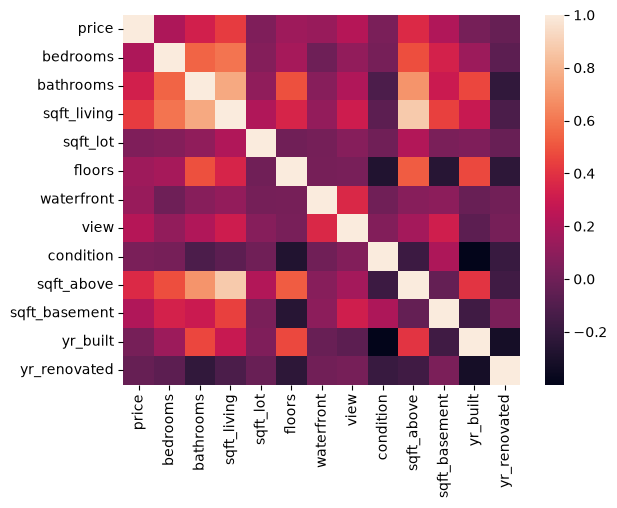

In [3]:
plt.Figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True))
plt.show()

<Axes: xlabel='sqft_above', ylabel='price'>

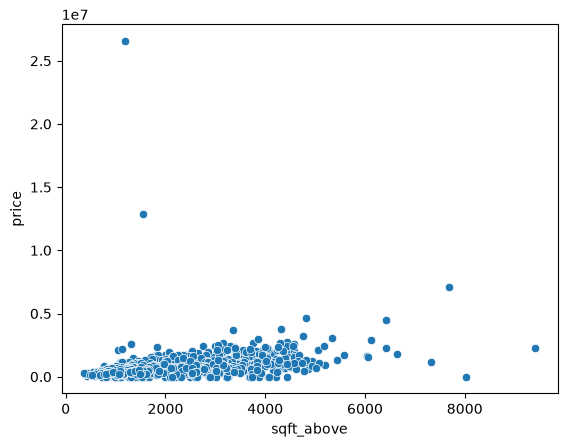

In [4]:
sns.scatterplot(x='sqft_above',y='price', data=df)

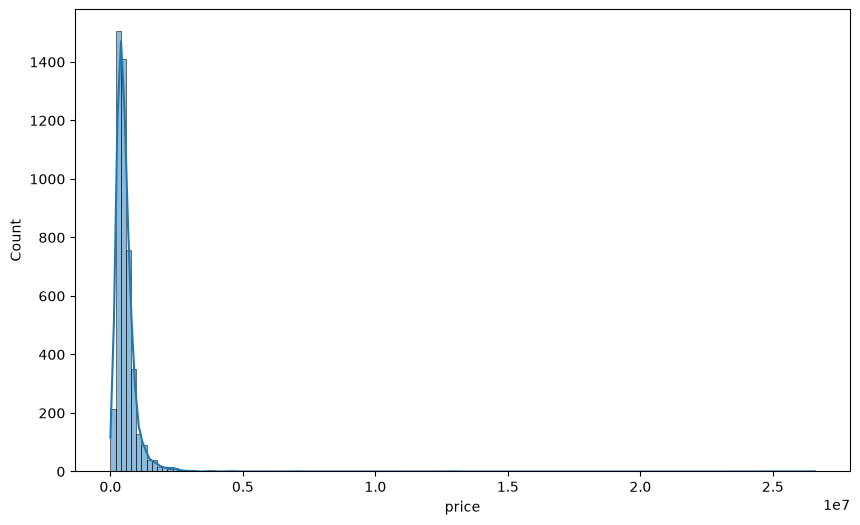

In [5]:
plt.figure(figsize=(10,6))
sns.histplot(df['price'], kde=True)
plt.show()

Text(0.5, 0, 'log_price')

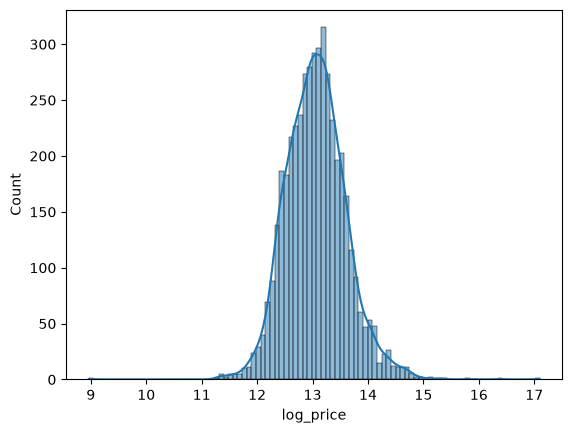

In [6]:
df = df[df['price']>0]
sns.histplot(np.log1p(df['price']), kde=True)
plt.xlabel('log_price')

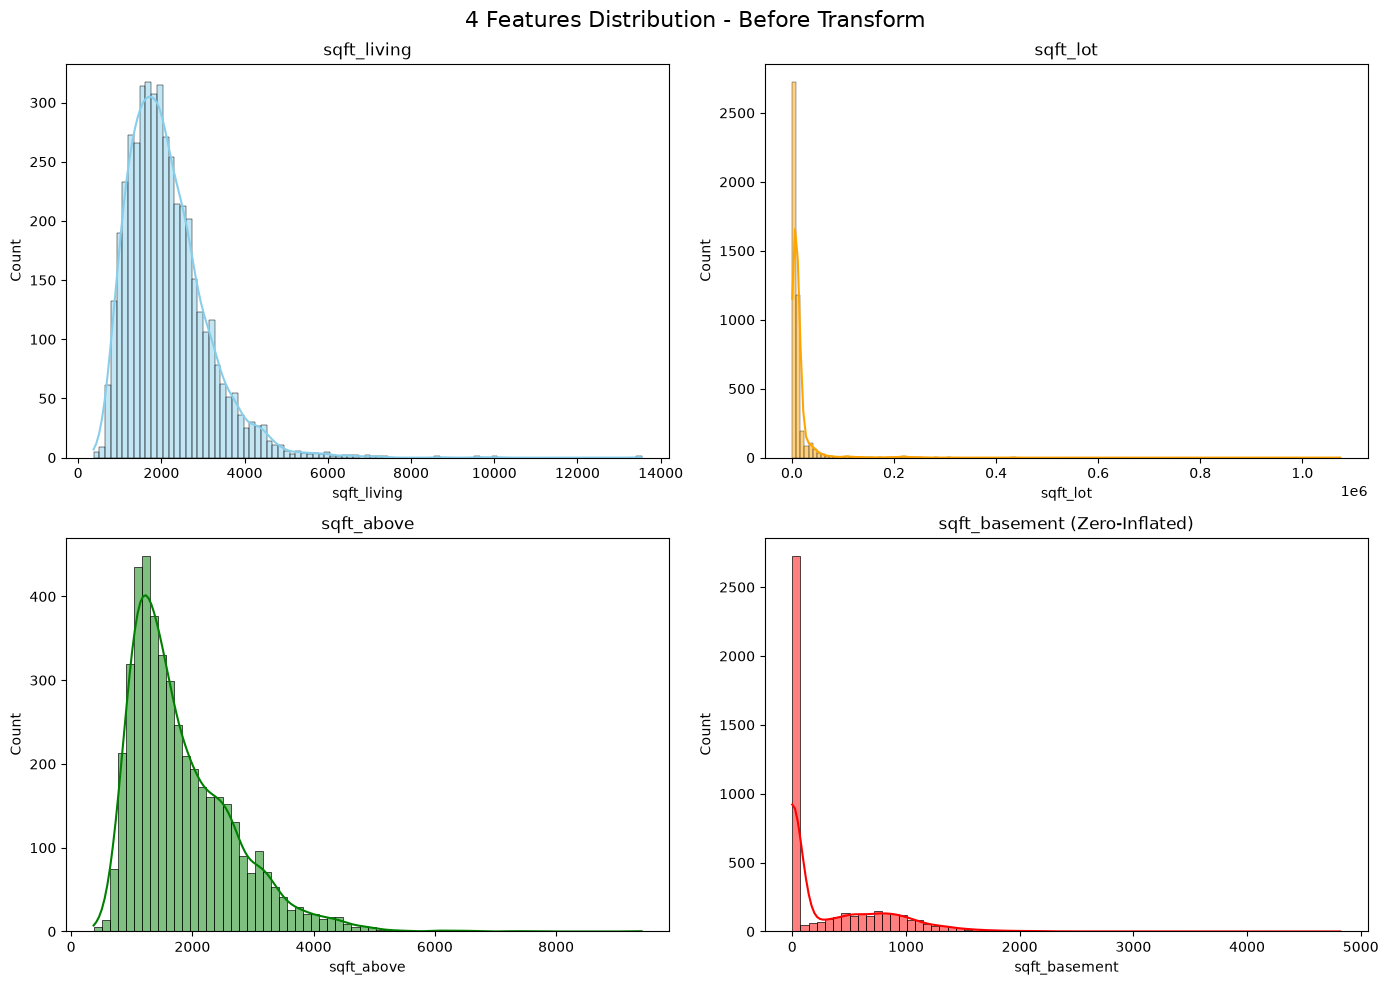

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('4 Features Distribution', fontsize=16)

# Graph 1
sns.histplot(df['sqft_living'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('sqft_living')
axes[0, 0].set_xlabel('sqft_living')
axes[0, 0].set_ylabel('Count')

# Graph 2
sns.histplot(df['sqft_lot'], kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('sqft_lot')
axes[0, 1].set_xlabel('sqft_lot')

# Graph 3
sns.histplot(df['sqft_above'], kde=True, ax=axes[1, 0], color='green')
axes[1, 0].set_title('sqft_above')
axes[1, 0].set_xlabel('sqft_above')

# Graph 4
sns.histplot(df['sqft_basement'], kde=True, ax=axes[1, 1], color='red')
axes[1, 1].set_title('sqft_basement (Zero-Inflated)')
axes[1, 1].set_xlabel('sqft_basement')

plt.tight_layout()
plt.show()

In [7]:
#Outliers
num_features = df.select_dtypes(include='number') #int64 or float 64
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((num_features < lower_bound) | (num_features > upper_bound))
print(outliers.sum())

price            240
bedrooms         115
bathrooms        130
sqft_living      128
sqft_lot         540
floors             0
waterfront        30
view             448
condition          6
sqft_above       111
sqft_basement     83
yr_built           0
yr_renovated       0
dtype: int64


# Feature Engeering

In [8]:
print(df.columns)

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='str')


In [9]:
df['date'] = pd.to_datetime(df['date'])
df['month_sold'] = df['date'].dt.month
df['year_sold'] = df['date'].dt.year

In [18]:
df['yr_renovated'] = np.where(df['yr_renovated']==0,df['yr_built'],df['yr_renovated'])

In [10]:
df['city'].value_counts().index[:12].tolist()

['Seattle',
 'Renton',
 'Bellevue',
 'Redmond',
 'Kirkland',
 'Issaquah',
 'Kent',
 'Auburn',
 'Sammamish',
 'Federal Way',
 'Shoreline',
 'Woodinville']

In [11]:
top_cities = ['Seattle',
 'Renton',
 'Bellevue',
 'Redmond',
 'Kirkland',
 'Issaquah',
 'Kent',
 'Auburn',
 'Sammamish',
 'Federal Way',
 'Shoreline',
 'Woodinville']

def Grouped_Countries(a):
    if a in  top_cities:
        return a
    else:
        return 'other'

df['grouped_cities'] = df['city'].apply(Grouped_Countries)

In [12]:
print(df['grouped_cities'].value_counts())

grouped_cities
Seattle        1561
other           898
Renton          291
Bellevue        281
Redmond         235
Kirkland        187
Issaquah        186
Kent            184
Auburn          175
Sammamish       171
Federal Way     145
Shoreline       123
Woodinville     114
Name: count, dtype: int64


In [13]:
print(df.columns)

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country', 'month_sold', 'year_sold', 'grouped_cities'],
      dtype='str')


In [14]:
display(df['statezip'].value_counts())

statezip
WA 98103    148
WA 98052    135
WA 98117    132
WA 98115    129
WA 98006    109
           ... 
WA 98047      6
WA 98288      3
WA 98050      2
WA 98354      2
WA 98068      1
Name: count, Length: 77, dtype: int64

In [15]:
top_statezips = ['WA 98103', 'WA 98052', 'WA 98117', 'WA 98115', 'WA 98006', 'WA 98059',
       'WA 98034', 'WA 98042', 'WA 98053', 'WA 98038', 'WA 98027', 'WA 98058',
       'WA 98074', 'WA 98133', 'WA 98023', 'WA 98033', 'WA 98125', 'WA 98029',
       'WA 98155', 'WA 98092', 'WA 98075', 'WA 98040', 'WA 98056', 'WA 98144',
       'WA 98118', 'WA 98126', 'WA 98004', 'WA 98065', 'WA 98112', 'WA 98199',]

def Grouped_Statezips(a):
    if a in top_statezips:
        return a
    else:
        return 'other'

df['grouped_statezips'] = df['statezip'].apply(Grouped_Statezips)

In [16]:
print(df.columns)

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country', 'month_sold', 'year_sold', 'grouped_cities',
       'grouped_statezips'],
      dtype='str')


In [27]:
skewed_col = ['sqft_basement', 'sqft_above', 'sqft_living', 'sqft_lot']

normal_col = ['bedrooms', 'bathrooms',
       'floors', 'waterfront', 'view', 'condition',
       'yr_built', 'yr_renovated','month_sold', 'year_sold']

ohe_col = ['gruped_cities','grouped_statezips']

feature_col = normal_col + skewed_col + ohe_col